Shahlo Solieva

10/14/2026

**Figure S1** Comparing FAST vs Folding@home simulations

In [1]:
# import all necessary packages
import numpy as np
import matplotlib.pyplot as plt
import mdtraj as md 

FAST_BASE_PATH = "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/RMSF"
FAH_BASE_PATH =  "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/RMSF"
CLUSTER_BASE = "/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/clustering/radius_15_variable/data"
fig_base_path=f'{FAST_BASE_PATH}/figures/manuscript'

# Helper functions

In [2]:
def load_and_split_rmsf(BASE_PATH, system_name, vh_end):
    """
    Load rmsf for given system, split into hc and lc data. 
    """
    DATA_PATH = f"{BASE_PATH}/data/apo/{system_name}/VHC_VLC_CA_RMSF.npy"
    rmsf = np.load(DATA_PATH, allow_pickle=True)*10 

    hc = rmsf[:vh_end]
    lc = rmsf[vh_end:]
    return hc, lc

def calculate_95CI_and_split(BASE_PATH, system_name, vh_end, n_straps):
    """
    Load bootstrapped (n=1000) rmsf for given system, split into hc and lc data. 
    """
    DATA_PATH = f"{BASE_PATH}/data/apo/{system_name}/n{n_straps}_bootstraps_VHC_VLC_CA_RMSF_avgs.npy"

    rmsfs_all_average = np.load(DATA_PATH)*10
    ci_low  = np.percentile(rmsfs_all_average, 2.5,  axis=0) 
    ci_high = np.percentile(rmsfs_all_average, 97.5, axis=0)  
    ci_hc   = [ci_low[:vh_end], ci_high[:vh_end]]  # ci low for HC, ci high for HC
    ci_lc   = [ci_low[vh_end:], ci_high[vh_end:]] 
    return ci_hc, ci_lc 

def get_bar_info(basepath, Ab_ranges, n_straps, CI=None):
    if CI:
        hc_rmsf, lc_rmsf =    load_and_split_rmsf(basepath, Ab_ranges[0], Ab_ranges[2])
        hc_ci,   lc_ci   =    calculate_95CI_and_split(basepath, Ab_ranges[0], Ab_ranges[2], n_straps)
        return [hc_rmsf, lc_rmsf, hc_ci,   lc_ci]
    else: 
        hc_rmsf, lc_rmsf =    load_and_split_rmsf(basepath, Ab_ranges[0], Ab_ranges[2])
        return [hc_rmsf, lc_rmsf]

# combined rmsf

In [3]:
Ab_ranges_list_FAST=[[("CH103_naive_VC",  1, 121, 1, 108), ("CH103_mature_VC", 1, 121, 1, 105)],
                    [("CH65_naive_VC",   1, 126, 1, 108),  ("CH65_mature_VC",  1, 126, 1, 108)],
                    [("PGT121_naive_lambda_VC",1, 132, 1, 109),("PGT121_mature_lambda_VC", 1, 132, 1, 105)],
                    [("Ab118_naive_VC", 1, 125, 1, 108), ("Ab118_mature_VC", 1, 131, 1, 108)],
                    [("CAP256_naive_VC",1, 144, 1, 111), ("CAP256_mature_VC", 1, 145, 1, 111)]
                ] 
Ab_ranges_list_FAH = Ab_ranges_list_FAST 

	Naive: [1.5941843503640152, 1.237290693283281] [1.2653111855973416, 1.2094917925220985] [1.8772906769570281, 1.3216670339817773]
CH103_naive_VC Naive: overlap in CI
	 CH103_mature_VC ('CH103_mature_VC', 1, 121, 1, 105)
		Mature: [0.8516937789859528, 0.8505469183123371] [0.6992821100524612, 0.8416958340642554] [0.9806181262811259, 0.8692621566760597]
CH103_mature_VC Mature: overlap in CI
	Naive: [1.1324129494747126, 1.2653527485703935] [0.9396136945185986, 1.2351817457994956] [1.2774054599873732, 1.355766346700178]
CH65_naive_VC Naive: overlap in CI
	 CH65_mature_VC ('CH65_mature_VC', 1, 126, 1, 108)
		Mature: [0.8902107650579537, 1.0556936111123014] [0.7563485772029376, 1.0386521739486425] [1.0137152339956677, 1.0910644148248092]
	Naive: [1.0398764186863922, 0.8704960032724799] [0.8884771092471003, 0.8599671051219665] [1.263725475266614, 0.8814108142103494]
	 PGT121_mature_lambda_VC ('PGT121_mature_lambda_VC', 1, 132, 1, 105)
		Mature: [1.3500697612527839, 1.2905368633233694] [1.12202

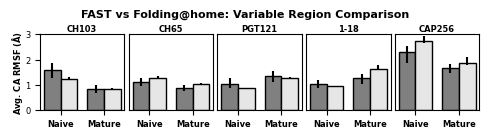

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(5, 1.6), sharey=True)

labels=[ 'CH103','CH65','PGT121', '1-18','CAP256']

for i in range(len(labels)):
    # # -------------------------------
    # # -------------------------------
    # #       Naive simulations
    # # -------------------------------
    # # -------------------------------
# 
    # # -------------------------------
    # Get rmsf info for FAST and FAH
    #print('\n')
    #print('\t',Ab_ranges_list_FAST[i][0], Ab_ranges_list_FAH[i][0])
    hc_rmsf, lc_rmsf, hc_ci, lc_ci = get_bar_info(FAST_BASE_PATH, Ab_ranges_list_FAST[i][0], '1000',CI=True)
    hc_rmsf_fah, lc_rmsf_fah, hc_ci_fah, lc_ci_fah = get_bar_info(FAH_BASE_PATH,Ab_ranges_list_FAH[i][0], '100',CI=True)

    # -------------------------------
    # Calculate averages for plotting
    low_ci =  [np.average(np.concatenate([hc_ci[0],lc_ci[0]])), np.average(np.concatenate([hc_ci_fah[0],lc_ci_fah[0]]))]
    high_ci = [np.average(np.concatenate([hc_ci[1],lc_ci[1]])), np.average(np.concatenate([hc_ci_fah[1],lc_ci_fah[1]]))]
    avg_data =[np.average(np.concatenate([hc_rmsf,lc_rmsf])),   np.average(np.concatenate([hc_rmsf_fah,lc_rmsf_fah]))]
    errs = [[avg_data[0]-low_ci[0], high_ci[0]-avg_data[0]], [avg_data[1]-low_ci[1], high_ci[1]-avg_data[1]]]
    print('\tNaive:', avg_data, low_ci, high_ci)  
    if max(low_ci[0], low_ci[1]) <= min(high_ci[0], high_ci[1]):
        print(Ab_ranges_list_FAST[i][0][0], 'Naive: overlap in CI')

    # -------------------------------
    # Plot naive data
    axes[i].bar([0.2,1.2],avg_data, yerr=np.array(errs).T, width=1, edgecolor='k', color=['0.5','0.9'], error_kw=dict(ecolor=['k','k']))
    
    # -------------------------------
    # -------------------------------
    #       Mature simulations
    # -------------------------------
    # -------------------------------
    print('\t',Ab_ranges_list_FAST[i][1][0], Ab_ranges_list_FAH[i][1])

    #print(FAST_BASE_PATH,Ab_ranges_list_FAST[i][0], '1000')
    #print(FAH_BASE_PATH,Ab_ranges_list_FAH[i][0], '100')
    #print(Ab_ranges_list_FAST[i][0], Ab_ranges_list_FAH[i][0])
    
    # -------------------------------
    # Get rmsf info for FAST and FAH
    hc_rmsf, lc_rmsf, hc_ci, lc_ci = get_bar_info(FAST_BASE_PATH,Ab_ranges_list_FAST[i][1], '1000', CI=True)
    hc_rmsf_fah, lc_rmsf_fah, hc_ci_fah, lc_ci_fah = get_bar_info(FAH_BASE_PATH,Ab_ranges_list_FAH[i][1], '100', CI=True)

    # -------------------------------
    # Calculate averages for plotting
    low_ci =  [np.average(np.concatenate([hc_ci[0],lc_ci[0]])), np.average(np.concatenate([hc_ci_fah[0],lc_ci_fah[0]]))]
    high_ci = [np.average(np.concatenate([hc_ci[1],lc_ci[1]])), np.average(np.concatenate([hc_ci_fah[1],lc_ci_fah[1]]))]
    avg_data =[np.average(np.concatenate([hc_rmsf,lc_rmsf])),   np.average(np.concatenate([hc_rmsf_fah,lc_rmsf_fah]))]
    errs = [[avg_data[0]-low_ci[0], high_ci[0]-avg_data[0]], [avg_data[1]-low_ci[1], high_ci[1]-avg_data[1]]]
    print('\t\tMature:',avg_data, low_ci, high_ci)  
    if max(low_ci[0], low_ci[1]) <= min(high_ci[0], high_ci[1]):
        print(Ab_ranges_list_FAST[i][1][0], 'Mature: overlap in CI')

    # -------------------------------
    # Plot mature data
    axes[i].bar([3-.2,4-.2], avg_data, yerr=np.array(errs).T, width=1, edgecolor='k', color=['0.5','0.9'], error_kw=dict(ecolor=['k','k']))
    
    # -------------------------------
    # labels and such
    axes[i].set_title(f'{labels[i]}', fontsize=6, weight='bold', pad=2)
    axes[i].set_xticks([0.7, 3.3])
    axes[i].set_xticklabels(['Naive','Mature'], fontsize=6, weight='bold')

# fig.suptitle('Variable Region rmsf Comparison: FAST vs FAH', fontsize=8, y=1.1, weight='bold')
axes[0].set_ylabel('Avg. CA RMSF ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
axes[0].set_yticks([0,1,2,3,4,5,6,7])
axes[0].set_yticklabels([0,1,2,3,4,5,6,7], fontsize=6)
#axes[0].set_ylim([0,5.5])
axes[0].set_ylim([0,3.01])
for i in range(1,5):
    axes[i].yaxis.set_visible(False)
    axes[i].set_xticks([0.7, 3.3])
    axes[i].set_xticklabels(['Naive','Mature'], fontsize=6, weight='bold')
fig.suptitle('FAST vs Folding@home: Variable Region Comparison', fontsize=8, y=0.84, weight='bold')
plt.tight_layout()
plt.subplots_adjust(wspace=0.05)

plt.savefig(f"../figures/manuscript/FigS1_FAST_v_FAH_rmsf_per_region_Naive_Mature_FASTci_FAHci-updated.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# Legend

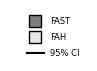

In [19]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

plt.figure(figsize=[1,0.4])
plt.axis('off')

point = Line2D([0], [0], markerfacecolor='0.5', label='FAST' , marker='s', markersize=8, 
         markeredgecolor='k',  linestyle='')
line = Line2D([0], [0], label='95% CI', color='k')

#patch2 = mpatches.Patch(color='0.9', label='FAH', markerfacecolor='k')   
point2 = Line2D([0], [0], markerfacecolor='0.9', label='FAH' , marker='s', markersize=8, 
         markeredgecolor='k',  linestyle='')
#line2 = Line2D([0], [0], label='st. dev.', color='gray')

plt.legend(handles=[point, point2, line], frameon=False, fontsize=6, ncol=1,labelspacing=0.8, )
#plt.savefig(f"{FIGURE_PATH}/FAST_v_FAH_rmsf_per_region_Naive_Mature_FASTci_FAHci_legend.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# per residue plot

In [7]:
def plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type):
    if Ab_type == 'Naive':
        FAST_c = '#80bfff'
    if Ab_type == 'Mature':
        FAST_c = '#004080'
        
    plt.figure(figsize= [2.3,1.4]) 
    hc_rmsf, lc_rmsf, hc_ci, lc_ci = get_bar_info(FAST_BASE_PATH, Ab_FAST, '1000', CI=True)
    hc_rmsf_fah, lc_rmsf_fah, hc_ci_fah, lc_ci_fah = get_bar_info(FAH_BASE_PATH,Ab_FAH,'100', CI=True)
    x = np.arange(1,len(hc_rmsf)+1)
    plt.plot(x, hc_rmsf, label=f'FAST',color=FAST_c, linewidth=0.8)
    plt.fill_between(x, hc_ci[0], hc_ci[1], color=FAST_c, alpha=0.6, linewidth=0.5)
    plt.plot(x, hc_rmsf_fah, label=f'FAH',  color='k', linewidth=0.8)
    plt.fill_between(x, hc_ci_fah[0], hc_ci_fah[1], color='k', alpha=0.6, linewidth=0.5)
    plt.title(f"{label} {Ab_type}: Variable HC", fontsize=6, weight='bold', pad = 0)
    plt.xlabel('Residue Number', fontsize=6, weight='bold')
    plt.xticks([0,50,100],fontsize=6)
    plt.yticks([0,2,4,6],fontsize=6)
    plt.ylim(0,7)
    if label == 'CAP256':
        plt.yticks([0,4,8,12,16],fontsize=6)
        plt.ylim(0,16)
    plt.legend(fontsize=6)
    plt.ylabel('CA RMSF ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
    #FIGURE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/per_resi_rmsf/figures/manuscript/FAST_vs_FAH'
    plt.tight_layout()
    plt.savefig(f'../figures/manuscript/FigS1_{label}_{Ab_type}_HC_ci.pdf', dpi=300, transparent=True, bbox_inches='tight')
    plt.show()

    plt.figure(figsize= [1.8,1.4]) 
    x = np.arange(1,len(lc_rmsf)+1)
    plt.plot(x, lc_rmsf, label=f'FAST',color=FAST_c, linewidth=0.8)
    plt.fill_between(x, lc_ci[0], lc_ci[1], color=FAST_c, alpha=0.6, linewidth=0.5)
    plt.plot(x, lc_rmsf_fah, label=f'FAH',  color='k', linewidth=0.8)
    plt.fill_between(x, lc_ci_fah[0], lc_ci_fah[1], color='k', alpha=0.6, linewidth=0.5)
    plt.title(f"{label} {Ab_type}: Variable LC", fontsize=6, weight='bold', pad = 0)
    plt.xlabel('Residue Number', fontsize=6, weight='bold')
    plt.xticks([0,50,100],fontsize=6)
    plt.yticks([0,2,4,6],fontsize=6)
    plt.ylim(0,7)
    if label == 'CAP256':
        plt.yticks([0,4,8,12,16],fontsize=6)
        plt.ylim(0,16)
    plt.legend(fontsize=6)
    #plt.ylabel('CA RMSF ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
    plt.tight_layout()
    plt.savefig(f'../figures/manuscript/FigS1_{label}_{Ab_type}_LC_ci.pdf', dpi=300, transparent=True, bbox_inches='tight')
    plt.show()

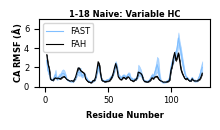

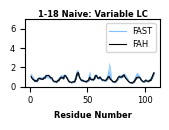

In [6]:
label = '1-18'
Ab_type = 'Naive'
Ab_FAH = ("Ab118_naive_VC", 1, 125, 1, 108)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)


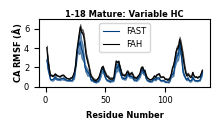

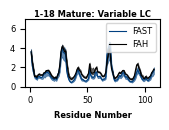

In [9]:
label = '1-18'
Ab_type = 'Mature'
Ab_FAH = ("Ab118_mature_VC", 1, 131, 1, 108)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)

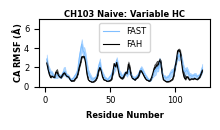

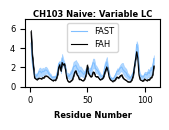

In [4]:
label = 'CH103'
Ab_type = 'Naive'
Ab_FAH = ("CH103_naive_VC", 1, 121, 1, 108)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)

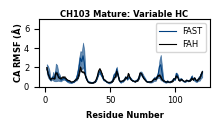

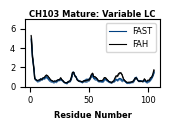

In [6]:
label = 'CH103'
Ab_type = 'Mature'
Ab_FAH = ("CH103_mature_VC", 1, 121, 1, 105)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)


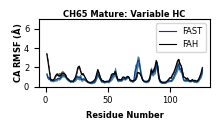

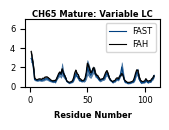

In [7]:
label = 'CH65'
Ab_type = 'Mature'
Ab_FAH = ("CH65_mature_VC",  1, 126, 1, 108)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)


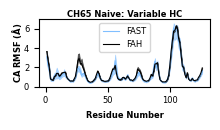

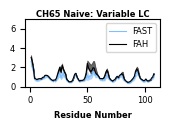

In [4]:
label = 'CH65'
Ab_type = 'Naive'
Ab_FAH = ("CH65_naive_VC",  1, 126, 1, 108)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)

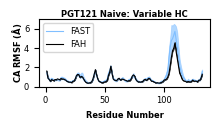

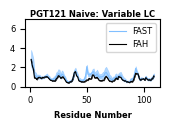

In [8]:
label = 'PGT121'
Ab_type = 'Naive'
Ab_FAH = ("PGT121_naive_lambda_VC",1, 132, 1, 109)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)


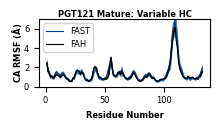

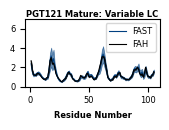

In [4]:
label = 'PGT121'
Ab_type = 'Mature'
Ab_FAH = ("PGT121_mature_lambda_VC",1, 132, 1, 105)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)


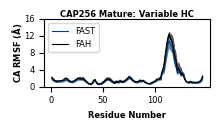

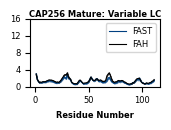

In [4]:
label = 'CAP256'
Ab_type = 'Mature'
Ab_FAH = ("CAP256_mature_VC",  1, 145, 1, 111)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)

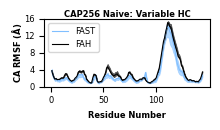

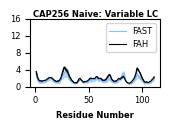

In [4]:
label = 'CAP256'
Ab_type = 'Naive'
Ab_FAH = ("CAP256_naive_VC",  1, 144, 1, 111)
Ab_FAST = Ab_FAH
plot_FAST_vs_FAH(Ab_FAST, Ab_FAH, label, Ab_type)